# Modeling sequential data with RNNs — a CNC machining cell

**Companion notebook to the lecture *Modeling sequential data using recurrent neural
networks*.**

Everything here runs on CPU in about six minutes and downloads nothing. The sequences are
synthetic but generated from a real machining error budget, so the channels, the units and
the failure mechanism are the ones you would meet on a shop floor.

## The running example

A CNC turning cell logs five channels at 50 Hz for every part it machines:

| channel | unit | what it is |
|---|---|---|
| `spindle_current` | A | load proxy |
| `vibration_rms` | g | accelerometer, 10 ms window |
| `spindle_temp` | °C | first-order thermal lag driven by the load |
| `feed_rate` | — | commanded feed, normalised |
| `op_code` | categorical | G-code block: approach, rough, finish, retract, dwell |

Cycles last between 110 and 150 samples depending on the part, so the batch is **ragged**
and we will have to pad and pack it. After the cycle the part is gauged and the finished
diameter error is recorded: `undersize`, `in tolerance`, or `oversize`.

### Why this task needs memory

Two independent faults move the finished diameter in **opposite** directions.

* A **hard inclusion** in the casting micro-chips the cutting edge early in roughing, at
  around sample 25. A chipped edge rubs rather than cuts, the workpiece heats, and once it
  cools the feature comes out **undersize**, about −21 µm.
* A **heavy finishing pass**, programmed around sample 100, deflects the tool away from the
  work and leaves the feature **oversize**, about +21 µm.

Either fault alone puts the part outside the ±12 µm tolerance band. With **both** faults the
two errors very nearly cancel and the part is good. So the label depends on an event at
t ≈ 25 *and* a load level at t ≈ 100, and **neither end of the cycle predicts it alone**.
Section 11 proves that experimentally.

Error budgets with terms of opposite sign that partly cancel are completely ordinary in
precision machining; what makes this one a good teaching example is that the two terms are
120 samples apart.

## Learning objectives

By the end you should be able to:

1. Say what makes data sequential, and name the five input/output shapes a sequence model
   can have.
2. Write the forward pass of an RNN by hand and reproduce `nn.RNN` exactly.
3. Explain why backpropagation through time multiplies Jacobians, and predict from the
   spectral radius of $W_{hh}$ whether gradients will vanish or explode.
4. **Measure** how far back a gradient actually reaches, instead of assuming.
5. Write the LSTM gate equations and say what each gate is for.
6. Handle ragged batches with `pad_sequence` and `pack_padded_sequence`, and know what breaks
   if you skip the packing.
7. Train a many-to-one classifier and a many-to-many autoregressive generator, and control
   the generator's randomness with a temperature.

## Prerequisites

`nn.Module`, `DataLoader` and the training loop from the PyTorch-mechanics lecture;
the chain rule; basic linear algebra (eigenvalues).

---
## 0. Environment

In [1]:
import sys, platform, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

print("python     ", sys.version.split()[0], "on", platform.system())
print("torch      ", torch.__version__)
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)
print("threads    ", torch.get_num_threads())
torch.set_num_threads(min(8, torch.get_num_threads()))

python      3.11.15 on Linux
torch       2.14.0+cu130
numpy       2.4.4
matplotlib  3.10.9
threads     2


In [2]:
SURF, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = ("#2a78d6", "#eb6834", "#1baf7a",
                                           "#eda100", "#e34948", "#4a3aa7")
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "lines.linewidth": 1.8,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

---
## 1. What makes data sequential

Everything before this lecture assumed the training examples were **independent and
identically distributed**: shuffle them and nothing changes. A sequence breaks that
assumption by definition — the order carries information. Sample 25 of a machining cycle
means something different from sample 100 of the same cycle.

**Sequential vs time series.** A time series is a sequence whose elements carry a timestamp.
Our machining cycles are time series. A G-code program, a DNA strand and a sentence are
sequences but not time series: they are ordered without being clocked. Everything in this
lecture applies to both.

### The five shapes of a sequence problem

| shape | input | output | our example |
|---|---|---|---|
| standard | vector | vector | not a sequence problem — use an MLP |
| **many-to-one** | sequence | one label | **the whole cycle → scrap class** (project one) |
| one-to-many | vector | sequence | a part number → the expected cycle |
| **many-to-many, synchronised** | sequence | sequence, aligned | a per-sample anomaly flag |
| **many-to-many, delayed** | sequence | sequence, offset | next-sample forecasting (project two) |

Choosing the shape first is what decides where you read the output from: the last hidden
state for many-to-one, every hidden state for synchronised many-to-many.

---
## 2. The data

The generator below renders one cycle analytically. Read it — knowing exactly what produced
the labels is what lets us say later whether a model *should* have got them right.

Two details are deliberate and load-bearing:

* the inclusion raises **current and vibration together**, while the benign coolant surges
  scattered through the cycle raise only current. So a single threshold on vibration
  identifies the event — detecting it is easy, and **remembering** it is the hard part;
* nothing after the inclusion carries a trace of it. A micro-chip is far below the
  load-sensing threshold for the rest of the cut. That is a modelling choice, and it is the
  one that makes this a pure memory problem.

In [3]:
FS = 50.0
CHANNELS = ["spindle_current", "vibration_rms", "spindle_temp", "feed_rate"]
OPS = ["approach", "rough", "finish", "retract", "dwell"]
N_OPS = len(OPS)
CLASSES = ["undersize", "in tolerance", "oversize"]

CHIP_UM, DEFL_UM, SIGMA_UM, TOL_UM = 21.0, 21.0, 4.0, 12.0

PHASES = [("approach", 0.09), ("rough", 0.40), ("dwell", 0.05),
          ("finish", 0.34), ("retract", 0.12)]
OP_OF = {"approach": 0, "rough": 1, "finish": 2, "retract": 3, "dwell": 4}
LEVEL = {"approach": (2.0, 0.25, 0.85), "rough": (11.0, 1.60, 0.55),
         "dwell": (1.2, 0.15, 0.00), "finish": (5.2, 0.70, 0.35),
         "retract": (1.5, 0.20, 0.95)}
FINISH_HEAVY = (8.6, 1.15, 0.30)
TAU_TEMP, TEMP_GAIN, TEMP_AMBIENT = 4.0, 1.15, 22.0


def _phase_bounds(T):
    frac = np.array([f for _, f in PHASES], dtype=float)
    frac = frac / frac.sum()
    n = np.maximum(3, np.round(frac * T).astype(int))
    n[-1] += T - n.sum()
    starts = np.concatenate([[0], np.cumsum(n)[:-1]])
    return [(PHASES[i][0], int(starts[i]), int(starts[i] + n[i]))
            for i in range(len(PHASES))]


def render_cycle(chip, heavy, rng, T=None):
    '''One machining cycle: (T,4) signals, (T,) op codes, diameter error in um.'''
    if T is None:
        T = int(rng.integers(110, 151))
    cur = np.zeros(T); vib = np.zeros(T); feed = np.zeros(T)
    op = np.zeros(T, dtype=np.int64)

    gain = rng.uniform(0.88, 1.12)
    offset = rng.uniform(-0.4, 0.4)
    noise_c = rng.uniform(0.18, 0.40)
    noise_v = rng.uniform(0.04, 0.10)

    for name, a, b in _phase_bounds(T):
        lv = FINISH_HEAVY if (name == "finish" and heavy) else LEVEL[name]
        n = b - a
        ramp = np.clip(np.linspace(0, 3.0, n), 0, 1)
        ramp = np.clip(np.minimum(ramp, ramp[::-1] * 3.0), 0, 1)
        cur[a:b] = lv[0] * ramp
        vib[a:b] = lv[1] * ramp
        feed[a:b] = lv[2]
        op[a:b] = OP_OF[name]

    rough_a, rough_b = [(s, e) for nm, s, e in _phase_bounds(T) if nm == "rough"][0]
    if chip:                                   # current AND vibration jump
        t0 = int(rng.integers(rough_a + 2, rough_a + max(3, (rough_b - rough_a) // 2)))
        t1 = min(t0 + int(rng.integers(3, 6)), rough_b)
        cur[t0:t1] += rng.uniform(7.5, 10.5)
        vib[t0:t1] += rng.uniform(2.4, 3.2)

    for _ in range(rng.integers(1, 4)):        # coolant surges: current only
        t0 = int(rng.integers(2, T - 6))
        dur = int(rng.integers(3, 6))
        cur[t0:t0 + dur] += rng.uniform(6.0, 9.5)
        vib[t0:t0 + dur] += rng.uniform(0.0, 0.22)

    alpha = 1.0 - np.exp(-1.0 / (TAU_TEMP * FS))
    temp = np.empty(T); tprev = TEMP_AMBIENT + rng.uniform(-1.5, 1.5)
    for t in range(T):
        tprev += alpha * (TEMP_AMBIENT + TEMP_GAIN * cur[t] - tprev)
        temp[t] = tprev

    cur = gain * cur + offset + rng.normal(0, noise_c, T)
    vib = gain * vib + rng.normal(0, noise_v, T)
    temp = temp + rng.normal(0, 0.12, T)
    feed = feed + rng.normal(0, 0.012, T)
    x = np.stack([cur, vib, temp, feed], axis=1).astype(np.float32)

    delta = (-CHIP_UM * chip) + (DEFL_UM * heavy) + rng.normal(0, SIGMA_UM)
    return x, op, float(delta)


def make_dataset(n, seed=7, p_chip=0.5, p_heavy=0.5):
    rng = np.random.default_rng(seed)
    xs, ops, lens, ys, deltas, chips, heavies = [], [], [], [], [], [], []
    for _ in range(n):
        chip = bool(rng.random() < p_chip)
        heavy = bool(rng.random() < p_heavy)
        x, op, delta = render_cycle(chip, heavy, rng)
        xs.append(x); ops.append(op); lens.append(len(op))
        deltas.append(delta); chips.append(chip); heavies.append(heavy)
        ys.append(0 if delta < -TOL_UM else (2 if delta > TOL_UM else 1))
    y = np.array(ys, dtype=np.int64)
    return {"x": xs, "op": ops, "len": np.array(lens), "y": y,
            "scrap": (y != 1).astype(np.int64), "delta": np.array(deltas),
            "chip": np.array(chips), "heavy": np.array(heavies)}


tr = make_dataset(800, seed=7)
va = make_dataset(300, seed=108)
te = make_dataset(600, seed=209)
for nm, d in (("train", tr), ("valid", va), ("test ", te)):
    print(f"{nm}  n={len(d['y'])}  lengths {d['len'].min()}-{d['len'].max()}"
          f"  class counts {np.bincount(d['y'])}  scrap {d['scrap'].mean():.3f}")

train  n=800  lengths 110-150  class counts [191 422 187]  scrap 0.472
valid  n=300  lengths 110-150  class counts [ 70 143  87]  scrap 0.523
test   n=600  lengths 110-150  class counts [147 286 167]  scrap 0.523


In [4]:
# the 2x2 of faults -- this table is the whole task
print(f"{'inclusion':>10}{'heavy finish':>14}{'n':>6}{'mean Ø error':>14}   outcome")
for c in (0, 1):
    for h in (0, 1):
        m = (tr["chip"] == bool(c)) & (tr["heavy"] == bool(h))
        cls = np.bincount(tr["y"][m], minlength=3).argmax()
        print(f"{str(bool(c)):>10}{str(bool(h)):>14}{m.sum():>6}"
              f"{tr['delta'][m].mean():>+13.1f} µm   {CLASSES[cls]}")
print(f"\nirreducible label noise: sigma = {SIGMA_UM} µm against a ±{TOL_UM:.0f} µm band")

 inclusion  heavy finish     n  mean Ø error   outcome
     False         False   223         -0.4 µm   in tolerance
     False          True   188        +20.8 µm   oversize
      True         False   191        -21.0 µm   undersize
      True          True   198         +0.2 µm   in tolerance

irreducible label noise: sigma = 4.0 µm against a ±12 µm band


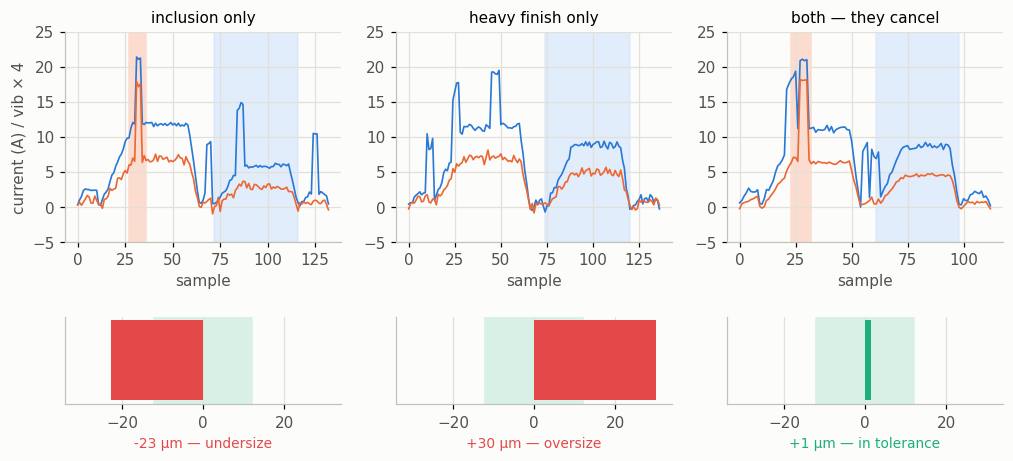

blue = spindle current, orange = vibration × 4, blue band = finishing pass,
orange band = the inclusion


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(11, 4.4),
                         gridspec_kw={"height_ratios": [2.4, 1], "hspace": .5})
for c, (chip, heavy, title) in enumerate([(True, False, "inclusion only"),
                                          (False, True, "heavy finish only"),
                                          (True, True, "both — they cancel")]):
    x, op, delta = render_cycle(chip, heavy, np.random.default_rng(40 + c))
    ax = axes[0, c]
    fin = np.where(op == 2)[0]
    ax.axvspan(fin[0], fin[-1], color="#cde2fb", alpha=.55, zorder=0)
    ax.plot(x[:, 0], color=BLUE, lw=1.1)
    ax.plot(x[:, 1] * 4, color=ORANGE, lw=1.1)
    if chip:
        k = int(np.argmax(x[:, 1]))
        ax.axvspan(k - 4, k + 5, color="#fbdcce", zorder=0)
    ax.set_title(title, fontsize=10); ax.set_ylim(-5, 25)
    ax.set_xlabel("sample")
    cls = 0 if delta < -TOL_UM else (2 if delta > TOL_UM else 1)
    axb = axes[1, c]
    axb.axvspan(-TOL_UM, TOL_UM, color="#d9f0e6", zorder=0)
    axb.barh([0], [delta], height=.5, color=AQUA if cls == 1 else RED)
    axb.set_xlim(-34, 34); axb.set_yticks([])
    axb.set_xlabel(f"{delta:+.0f} µm — {CLASSES[cls]}", fontsize=9,
                   color=AQUA if cls == 1 else RED)
axes[0, 0].set_ylabel("current (A) / vib × 4")
plt.show()
print("blue = spindle current, orange = vibration × 4, blue band = finishing pass,"
      "\norange band = the inclusion")

---
## 3. The dataflow in an RNN

A feedforward layer maps $x \rightarrow h \rightarrow o$. A recurrent layer adds one edge: the
hidden layer also receives **its own previous value**.

$$h^{(t)} = \sigma_h\!\left(W_{xh}x^{(t)} + W_{hh}h^{(t-1)} + b_h\right),
\qquad o^{(t)} = \sigma_o\!\left(W_{ho}h^{(t)} + b_o\right)$$

Three weight matrices, and — this is the part worth saying out loud — **they do not depend on
$t$**. The same $W_{hh}$ is applied at sample 3 and at sample 130. That is parameter sharing
across time, exactly as a CNN shares a kernel across space, and it is why an RNN handles a
sequence of any length with a fixed parameter count.

`nn.RNN` packs the biases as two vectors, `bias_ih` and `bias_hh`, rather than one. It is
mathematically redundant — their sum is the only thing that matters — but it keeps the input
and recurrent paths symmetric, which matters for the gated cells later.

In [6]:
torch.manual_seed(1)
rnn_layer = nn.RNN(input_size=4, hidden_size=2, num_layers=1, batch_first=True)
w_xh, w_hh = rnn_layer.weight_ih_l0, rnn_layer.weight_hh_l0
b_xh, b_hh = rnn_layer.bias_ih_l0, rnn_layer.bias_hh_l0
for nm, p in (("W_xh", w_xh), ("W_hh", w_hh), ("b_xh", b_xh), ("b_hh", b_hh)):
    print(f"{nm}: {tuple(p.shape)}")
print("\nbatch_first=True -> input is (batch, time, features)")

W_xh: (2, 4)
W_hh: (2, 2)
b_xh: (2,)
b_hh: (2,)

batch_first=True -> input is (batch, time, features)


In [7]:
# a three-step toy "cycle": the spindle ramping up
x_seq = torch.tensor([[1.0] * 4, [2.0] * 4, [3.0] * 4]).float()
output, hn = rnn_layer(torch.reshape(x_seq, (1, 3, 4)))

prev_h = torch.zeros((1, 2))
print(f"{'step':>5}{'manual':>34}{'nn.RNN':>34}")
worst = 0.0
for t in range(3):
    xt = torch.reshape(x_seq[t], (1, 4))
    ht = torch.matmul(xt, torch.transpose(w_xh, 0, 1)) + b_xh
    ot = torch.tanh(ht + torch.matmul(prev_h, torch.transpose(w_hh, 0, 1)) + b_hh)
    prev_h = ot
    man = ot.detach().numpy().ravel()
    aut = output[:, t].detach().numpy().ravel()
    worst = max(worst, float(np.abs(man - aut).max()))
    print(f"{t:>5}{str(man.round(6)):>34}{str(aut.round(6)):>34}")
print(f"\nmax |difference| = {worst:.3e}   (float32 round-off)")

 step                            manual                            nn.RNN
    0             [ 0.424984 -0.351001]             [ 0.424984 -0.351001]
    1             [ 0.64866  -0.312077]             [ 0.64866  -0.312077]
    2             [ 0.777357 -0.295868]             [ 0.777357 -0.295868]

max |difference| = 5.960e-08   (float32 round-off)


`tanh` is `nn.RNN`'s default activation, which is why the manual pass uses it. Note what the
loop does: it carries `prev_h` forward and nothing else. That one carried vector is the
entire memory of the network.

> **Hidden recurrence vs output recurrence.** We fed $h^{(t-1)}$ back into the hidden layer.
> You can instead feed $o^{(t-1)}$ back — into the hidden layer (output-to-hidden) or into the
> output layer (output-to-output). `nn.RNN` implements hidden-to-hidden, which is the most
> expressive of the three because $h$ is usually wider than $o$ and is not forced through the
> output nonlinearity. Output recurrence is what you get for free when you feed a model its
> own prediction, which is exactly what we do in project two.

---
## 4. Backpropagation through time, and why it goes wrong

Unfold the loop and an RNN is a very deep feedforward network whose layers share weights. The
loss is a sum over time, $L=\sum_{t=1}^{T}L^{(t)}$, and the gradient with respect to the
recurrent matrix is

$$\frac{\partial L^{(t)}}{\partial W_{hh}}
=\frac{\partial L^{(t)}}{\partial o^{(t)}}\times\frac{\partial o^{(t)}}{\partial h^{(t)}}
\times\left(\sum_{k=1}^{t}\frac{\partial h^{(t)}}{\partial h^{(k)}}
\times\frac{\partial h^{(k)}}{\partial W_{hh}}\right),
\qquad
\frac{\partial h^{(t)}}{\partial h^{(k)}}=\prod_{i=k+1}^{t}\frac{\partial h^{(i)}}{\partial h^{(i-1)}}$$

That last term is a **product of $t-k$ Jacobians**. Products of many matrices do one of two
things: they shrink to nothing or they blow up. For a single hidden unit with recurrent weight
$w$ the product is just $w^{\,t-k}$, and the behaviour is obvious.

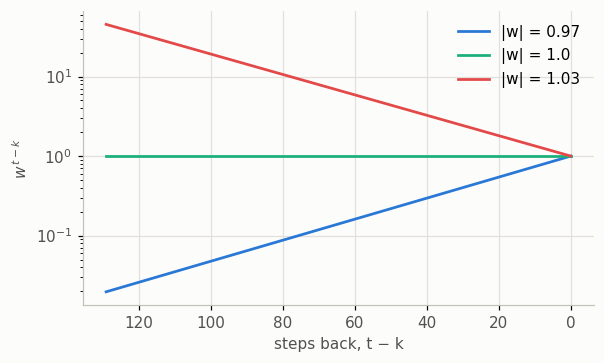

|w| = 0.97:  w^129 = 1.966e-02
|w| = 1.0:  w^129 = 1.000e+00
|w| = 1.03:  w^129 = 4.529e+01


In [8]:
T_demo = 130
k = np.arange(T_demo)[::-1]
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for w, c in ((0.97, BLUE), (1.00, AQUA), (1.03, RED)):
    ax.semilogy(np.arange(T_demo)[::-1], np.power(w, np.arange(T_demo)[::-1]),
                color=c, label=f"|w| = {w}")
ax.invert_xaxis()
ax.set_xlabel("steps back, t − k"); ax.set_ylabel(r"$w^{\,t-k}$")
ax.legend(); plt.tight_layout(); plt.show()

for w in (0.97, 1.00, 1.03):
    print(f"|w| = {w}:  w^129 = {w**129:.3e}")

A 3 % error in one recurrent weight becomes a factor of 50 over 130 steps, in one direction or
the other. For a matrix the relevant quantity is the **spectral radius** $\rho(W_{hh})$, the
largest absolute eigenvalue: below 1 the product contracts, above 1 it expands. Let us measure
it on the real thing.

In [9]:
# we need the model first -- defined here, trained in section 9
EMB_DIM, HID, GATE_BIAS = 4, 48, 2.0


def open_gates_(rnn, value=GATE_BIAS):
    '''Start the gate that controls memory in the "remember" position.

    PyTorch packs LSTM gate biases as [input, forget, cell, output] and GRU
    biases as [reset, update, new], so the same middle slice is the one we
    want in both cases.
    '''
    h = rnn.hidden_size
    with torch.no_grad():
        for name, p in rnn.named_parameters():
            if name.startswith("bias"):
                p[h:2 * h].fill_(value)


class SeqClassifier(nn.Module):
    def __init__(self, kind="lstm", hidden=HID, bidirectional=False,
                 gate_bias=0.0, n_cont=len(CHANNELS), n_class=len(CLASSES)):
        super().__init__()
        self.kind, self.bi = kind, bidirectional
        self.emb = nn.Embedding(N_OPS, EMB_DIM)
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = rnn_cls(n_cont + EMB_DIM, hidden, batch_first=True,
                           bidirectional=bidirectional)
        if gate_bias:
            open_gates_(self.rnn, gate_bias)
        feat = hidden * (2 if bidirectional else 1)
        self.head = nn.Sequential(nn.Linear(feat, 32), nn.ReLU(),
                                  nn.Linear(32, n_class))

    def forward(self, x, op, lengths):
        z = torch.cat([x, self.emb(op)], dim=-1)
        packed = nn.utils.rnn.pack_padded_sequence(
            z, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out = self.rnn(packed)
        hidden = out[1][0] if self.kind == "lstm" else out[1]
        h = torch.cat([hidden[-2], hidden[-1]], 1) if self.bi else hidden[-1]
        return self.head(h)


def pad_batch(d, idx=None):
    idx = np.arange(len(d["len"])) if idx is None else np.asarray(idx)
    Tmax = int(d["len"][idx].max())
    X = np.zeros((len(idx), Tmax, len(CHANNELS)), dtype=np.float32)
    O = np.zeros((len(idx), Tmax), dtype=np.int64)
    for k_, i in enumerate(idx):
        T = d["len"][i]
        X[k_, :T] = d["x"][i]
        O[k_, :T] = d["op"][i]
    return X, O, d["len"][idx].astype(np.int64), d["y"][idx]


allx = np.concatenate(tr["x"], axis=0)
MU, SD = allx.mean(0), allx.std(0) + 1e-8          # TRAIN statistics only


def prep(d):
    X, O, L, Y = pad_batch(d)
    return (torch.tensor((X - MU) / SD), torch.tensor(O),
            torch.tensor(L), torch.tensor(Y))


train, valid, test = prep(tr), prep(va), prep(te)
print("padded train tensor:", tuple(train[0].shape),
      " lengths", int(train[2].min()), "-", int(train[2].max()))

padded train tensor: (800, 150, 4)  lengths 110 - 150


In [10]:
loss_fn = nn.CrossEntropyLoss()
print(f"{'scale':>7}{'ρ(W_hh)':>10}{'gradient norm':>16}")
spectral = []
for sc in (0.6, 1.0, 1.4, 1.8, 2.2, 2.6, 3.0):
    torch.manual_seed(3)
    m = SeqClassifier("rnn")
    with torch.no_grad():
        m.rnn.weight_hh_l0.mul_(sc)
    rho = float(torch.linalg.eigvals(m.rnn.weight_hh_l0.detach()).abs().max())
    loss_fn(m(train[0][:32], train[1][:32], train[2][:32]), train[3][:32]).backward()
    gn = float(torch.sqrt(sum((p.grad ** 2).sum() for p in m.parameters()
                              if p.grad is not None)))
    spectral.append((sc, rho, gn))
    print(f"{sc:>7.1f}{rho:>10.3f}{gn:>16.3e}")

  scale   ρ(W_hh)   gradient norm
    0.6     0.330       4.511e-01
    1.0     0.551       4.763e-01


    1.4     0.771       4.992e-01


    1.8     0.991       5.581e-01
    2.2     1.212       6.463e-01
    2.6     1.432       1.331e+01
    3.0     1.652       2.785e+04


Flat while $\rho<1.2$, then five orders of magnitude in two steps. That is the exploding
gradient, and nothing about it is subtle once you look.

With PyTorch's default initialisation our RNN sits at $\rho\approx0.55$ — comfortably in the
**vanishing** regime, which is the far more common failure. The next section measures what
that costs.

---
## 5. How far back does the gradient actually reach?

This is the measurement to run before choosing an architecture, and almost nobody does it.
Run an **untrained** cell for $T$ steps, put a loss on the last step only, and record
$\|\partial L/\partial h^{(t)}\|$ for every $t$. It is a property of the architecture and its
initialisation, not of the data, so it costs seconds.

In [11]:
%%time
def gradient_decay(T=130, hidden=32, n_rep=12, seed=0):
    out = {}
    for tag, fb in (("rnn", 0.0), ("lstm", 0.0), ("lstm_open", GATE_BIAS)):
        kind = "rnn" if tag == "rnn" else "lstm"
        norms = np.zeros((n_rep, T))
        for r in range(n_rep):
            torch.manual_seed(seed + r)
            cell = (nn.RNNCell(4, hidden) if kind == "rnn"
                    else nn.LSTMCell(4, hidden))
            if fb:
                with torch.no_grad():
                    cell.bias_ih[hidden:2 * hidden].fill_(fb)
                    cell.bias_hh[hidden:2 * hidden].fill_(fb)
            x = torch.randn(1, T, 4) * 0.5
            h = torch.zeros(1, hidden); c = torch.zeros(1, hidden)
            hs = []
            for t in range(T):
                h, c = (cell(x[:, t], h), c) if kind == "rnn" else cell(x[:, t], (h, c))
                h.retain_grad(); hs.append(h)
            hs[-1].pow(2).sum().backward()
            norms[r] = [float(hh.grad.norm()) for hh in hs]
        med = np.median(norms, axis=0)
        out[tag] = med / max(med[-1], 1e-30)
    return out


gd = gradient_decay()
print(f"{'cell':>22}{'10 back':>12}{'50 back':>12}{'100 back':>12}")
for tag, lab in (("rnn", "vanilla RNN"), ("lstm", "LSTM, default init"),
                 ("lstm_open", "LSTM, gates open")):
    v = gd[tag]
    print(f"{lab:>22}{v[-10]:>12.2e}{v[-50]:>12.2e}{v[-100]:>12.2e}")

                  cell     10 back     50 back    100 back
           vanilla RNN    5.60e-03    4.42e-13    0.00e+00
    LSTM, default init    2.25e-03    2.75e-11    4.33e-21
      LSTM, gates open    2.13e-02    2.20e-02    3.80e-02
CPU times: user 2.23 s, sys: 11.3 ms, total: 2.24 s
Wall time: 1.56 s


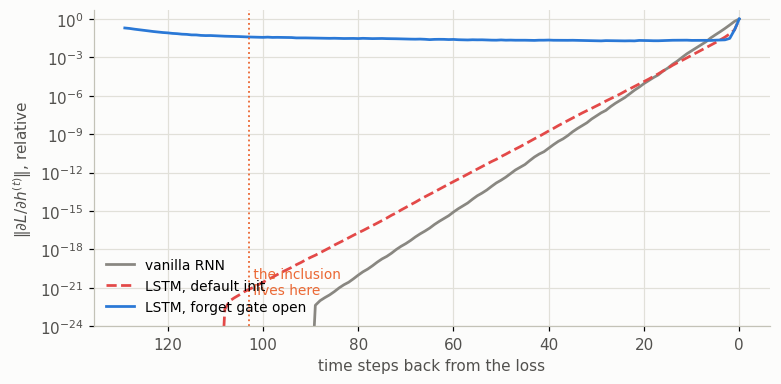

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
back = np.arange(len(gd["rnn"]))[::-1]
for tag, lab, c, ls in (("rnn", "vanilla RNN", MUTED, "-"),
                        ("lstm", "LSTM, default init", RED, "--"),
                        ("lstm_open", "LSTM, forget gate open", BLUE, "-")):
    ax.semilogy(back, np.maximum(gd[tag], 1e-30), color=c, ls=ls, label=lab)
ax.invert_xaxis(); ax.set_ylim(1e-24, 5)
ax.axvline(103, color=ORANGE, ls=":", lw=1.2)
ax.text(103, 3e-22, " the inclusion\n lives here", color=ORANGE, fontsize=9)
ax.set_xlabel("time steps back from the loss")
ax.set_ylabel(r"$\|\partial L/\partial h^{(t)}\|$, relative")
ax.legend(fontsize=9, loc="lower left"); plt.tight_layout(); plt.show()

Read the numbers, not the shape. One hundred steps back, a vanilla RNN's gradient is
**exactly zero in float32** and a default-initialised LSTM's is around $10^{-21}$ — far below
anything an optimiser can use. The inclusion event sits about 103 steps before the loss.

So the LSTM's famous gating does **not**, by itself, solve this. Section 7 shows the one line
that does.

> The reach of a default LSTM is still vastly better than a vanilla RNN's at 20–40 steps,
> which is the range most sequence tasks live in. Our task is deliberately past that range.

---
## 6. Two blunt instruments: clipping and truncation

**Gradient clipping** bounds the length of the update without changing its direction:

$$g \leftarrow g\cdot\frac{c}{\|g\|}\quad\text{whenever}\quad \|g\| > c$$

It is a cure for *exploding* gradients only. It does nothing for vanishing ones — scaling up a
zero is still zero.

raw gradient norm: max 88.6, median 12.4, min 3.73
100 % of steps exceeded the threshold and were rescaled to 1.0


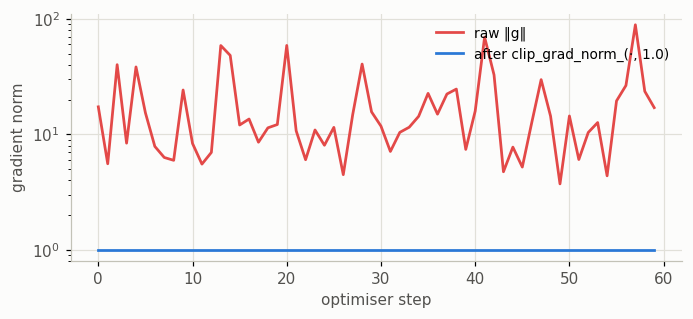

In [13]:
torch.manual_seed(3)
m = SeqClassifier("rnn")
with torch.no_grad():
    m.rnn.weight_hh_l0.mul_(2.6)             # push it into the exploding regime
opt = torch.optim.SGD(m.parameters(), lr=5e-3)
g = torch.Generator().manual_seed(3)
dl = DataLoader(TensorDataset(*train), batch_size=32, shuffle=True, generator=g)

raw, it = [], iter(dl)
for _ in range(60):
    try:
        xb, ob, lb, yb = next(it)
    except StopIteration:
        it = iter(dl); xb, ob, lb, yb = next(it)
    loss_fn(m(xb, ob, lb), yb).backward()
    raw.append(float(nn.utils.clip_grad_norm_(m.parameters(), 1.0)))
    opt.step(); opt.zero_grad()

raw = np.array(raw)
print(f"raw gradient norm: max {raw.max():.1f}, median {np.median(raw):.1f}, "
      f"min {raw.min():.2f}")
print(f"{100*(raw > 1.0).mean():.0f} % of steps exceeded the threshold and were rescaled to 1.0")
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.semilogy(raw, color=RED, label="raw ‖g‖")
ax.semilogy(np.minimum(raw, 1.0), color=BLUE, label="after clip_grad_norm_(·, 1.0)")
ax.set_xlabel("optimiser step"); ax.set_ylabel("gradient norm")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

**Truncated backpropagation through time (TBPTT)** is the other blunt instrument: run the
forward pass over the whole sequence but only backpropagate through the last $k$ steps,
detaching the hidden state at the boundary.

```python
h = None
for chunk in chunks_of(sequence, k):          # k = 20, say
    out, h = rnn(chunk, h)
    loss = loss_fn(out, target_chunk)
    loss.backward()
    opt.step(); opt.zero_grad()
    h = tuple(s.detach() for s in h)          # <- the truncation
```

TBPTT bounds memory and compute, and it stops gradients exploding across the full length. But
note what it costs on **our** task: truncating at 20 steps makes a 103-step dependency
unlearnable *by construction*. Truncation is a resource decision, not an accuracy one — never
set $k$ shorter than the dependency you are trying to learn.

---
## 7. LSTM cells

The LSTM (Hochreiter & Schmidhuber, 1997) adds a second state, the **cell state** $C^{(t)}$,
which travels from step to step with **no weight matrix applied to it** — only an element-wise
multiply and an element-wise add. That is the whole idea: a path along which the gradient is
multiplied by $f_t$ rather than by a Jacobian.

$$f_t=\sigma\!\left(W_{xf}x^{(t)}+W_{hf}h^{(t-1)}+b_f\right) \quad\text{forget: what to keep}$$
$$i_t=\sigma\!\left(W_{xi}x^{(t)}+W_{hi}h^{(t-1)}+b_i\right),\quad
\tilde C_t=\tanh\!\left(W_{xc}x^{(t)}+W_{hc}h^{(t-1)}+b_c\right) \quad\text{input: what to add}$$
$$o_t=\sigma\!\left(W_{xo}x^{(t)}+W_{ho}h^{(t-1)}+b_o\right) \quad\text{output: what to expose}$$
$$C^{(t)}=C^{(t-1)}\odot f_t\;+\;i_t\odot\tilde C_t,
\qquad h^{(t)}=o_t\odot\tanh\!\left(C^{(t)}\right)$$

The forget gate was not in the original 1997 cell; Gers, Schmidhuber & Cummins added it in
2000 because without it the cell state grew without bound.

**GRU** (Cho et al., 2014) merges the forget and input gates into one update gate and drops
the separate cell state: fewer parameters, usually comparable accuracy. We will measure both.

In [14]:
cell = nn.LSTMCell(4, 8)
print("an LSTM cell packs all four gates into two matrices:")
for nm, p in cell.named_parameters():
    print(f"  {nm:<10} {tuple(p.shape)}   = 4 × hidden rows, stacked [i, f, g, o]")
print(f"\nparameters, LSTM(8→48) vs GRU(8→48) vs RNN(8→48):")
for kind, cls in (("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)):
    n = sum(p.numel() for p in cls(8, 48, batch_first=True).parameters())
    print(f"  {kind:<5}{n:>8,}")

an LSTM cell packs all four gates into two matrices:
  weight_ih  (32, 4)   = 4 × hidden rows, stacked [i, f, g, o]
  weight_hh  (32, 8)   = 4 × hidden rows, stacked [i, f, g, o]
  bias_ih    (32,)   = 4 × hidden rows, stacked [i, f, g, o]
  bias_hh    (32,)   = 4 × hidden rows, stacked [i, f, g, o]

parameters, LSTM(8→48) vs GRU(8→48) vs RNN(8→48):
  RNN     2,784
  GRU     8,352
  LSTM   11,136


---
## 8. Initialise the gates open

Here is the practical result that the textbook treatment misses.

At initialisation every bias in `nn.LSTM` is drawn near zero, so $f_t\approx\sigma(0)=0.5$:
**the cell throws away half its memory at every single step**. Over our 103-step gap that is
$0.5^{103}\approx 10^{-31}$ of the original signal. The cell *can* learn to hold its forget
gate open, but it has to discover that from a gradient that has already vanished — a
chicken-and-egg problem.

Set the forget-gate bias to $+2$ instead and $f_t\approx 0.88$, giving
$0.88^{103}\approx 2\times10^{-6}$ — twenty-five orders of magnitude more signal to start
from. This is the trick from Gers et al. (2000), measured systematically by Jozefowicz,
Zaremba & Sutskever (2015), who recommend exactly this.

In PyTorch the LSTM gate biases are stored as one vector per layer in the order
`[input, forget, cell, output]`, so the forget slice is `[hidden : 2*hidden]`. A GRU stores
`[reset, update, new]`, and its update gate occupies the *same* slice — which is why one
helper works for both.

In [15]:
sig = lambda z: 1 / (1 + np.exp(-z))
print(f"{'forget-gate bias':>18}{'f at init':>12}{'f^103':>14}")
for b in (0.0, 1.0, 2.0, 3.0):
    print(f"{b:>18.1f}{sig(b):>12.3f}{sig(b)**103:>14.2e}")
print("\nthe helper, in full:")
import inspect
print(inspect.getsource(open_gates_))

  forget-gate bias   f at init         f^103
               0.0       0.500      9.86e-32
               1.0       0.731      9.71e-15
               2.0       0.881      2.10e-06
               3.0       0.953      6.71e-03

the helper, in full:
def open_gates_(rnn, value=GATE_BIAS):
    '''Start the gate that controls memory in the "remember" position.

    PyTorch packs LSTM gate biases as [input, forget, cell, output] and GRU
    biases as [reset, update, new], so the same middle slice is the one we
    want in both cases.
    '''
    h = rnn.hidden_size
    with torch.no_grad():
        for name, p in rnn.named_parameters():
            if name.startswith("bias"):
                p[h:2 * h].fill_(value)



---
## 9. Ragged batches: pad, pack, embed

Our cycles are 110–150 samples long, so a batch has to be padded to the longest member. That
creates a problem the padding alone does not solve: if you hand the padded tensor straight to
`nn.LSTM` and then read `hidden[-1]`, you get **the state after stepping through the padding**,
not the state at the end of the cycle. For a short sequence in a batch with a long one, that
can be dozens of steps of zeros.

`pack_padded_sequence` carries the true lengths alongside the data so the recurrent layer
stops each sequence at its own end. Use `enforce_sorted=False` and PyTorch sorts and unsorts
for you, returning `hidden` in the original batch order.

```python
# WRONG -- hidden[-1] is the state after T_max steps, padding included
out, (h, c) = lstm(padded)

# RIGHT
packed = nn.utils.rnn.pack_padded_sequence(padded, lengths.cpu(),
                                           batch_first=True, enforce_sorted=False)
out, (h, c) = lstm(packed)        # h[-1] is the state at each true last sample
```

**Embedding the categorical channel.** `op_code` is one of five G-code block types. One-hot
would work for five, but `nn.Embedding(5, 4)` is the general answer: a trainable lookup table
mapping each code to a dense vector, learned with the rest of the model. It is what you need
the moment the vocabulary is tool IDs or part numbers rather than five phases.

In [16]:
# what packing actually changes
torch.manual_seed(0)
lstm = nn.LSTM(6, 5, batch_first=True)
x = torch.randn(3, 10, 6)
lengths = torch.tensor([10, 4, 7])
x[1, 4:] = 0.0                                   # pad rows 1 and 2
x[2, 7:] = 0.0

_, (h_naive, _) = lstm(x)
packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True,
                                           enforce_sorted=False)
_, (h_packed, _) = lstm(packed)

print("sequence 1 has 4 real samples out of 10")
print("  hidden[-1] without packing:", h_naive[-1, 1].detach().numpy().round(4))
print("  hidden[-1] with packing   :", h_packed[-1, 1].detach().numpy().round(4))
diff = (h_naive[-1, 1] - h_packed[-1, 1]).abs().max().item()
print(f"  they differ by {diff:.4f}")
print("\nsequence 0 is full length, so packing changes nothing there:",
      bool(torch.allclose(h_naive[-1, 0], h_packed[-1, 0], atol=1e-6)))

emb = nn.Embedding(N_OPS, EMB_DIM)
print(f"\nnn.Embedding({N_OPS}, {EMB_DIM}) maps op codes [1,2,2,3] to:")
print(emb(torch.tensor([1, 2, 2, 3])).detach().numpy().round(3))

sequence 1 has 4 real samples out of 10
  hidden[-1] without packing: [-0.0877  0.1966  0.1572  0.0665 -0.0051]
  hidden[-1] with packing   : [-0.2086  0.1336 -0.0877 -0.2896 -0.1018]
  they differ by 0.3562

sequence 0 is full length, so packing changes nothing there: True

nn.Embedding(5, 4) maps op codes [1,2,2,3] to:
[[-0.369  1.218  0.255  0.274]
 [-0.561 -0.43  -0.333 -1.546]
 [-0.561 -0.43  -0.333 -1.546]
 [ 0.122 -1.077 -0.651 -1.62 ]]


---
## 10. Project one: many-to-one scrap classification

One training function, six models. Everything else — data, seeds, schedule, 22 epochs — is
held fixed, so any difference comes from the thing named in the first column.

The last model is not recurrent at all: a stack of **dilated 1-D convolutions** with dilations
1, 2, 4, …, 64, giving a receptive field of 255 samples. It sees the whole cycle in one
feedforward pass, with no gradient path through time at all. It is the modern alternative to
recurrence for fixed-horizon sequence tasks, and it ties directly back to the CNN lecture.

**This cell is the slow one: five minutes on two CPU cores.**

In [17]:
class DilatedTCN(nn.Module):
    '''Dilated 1-D convolutions: see the whole cycle without recurrence.'''
    def __init__(self, ch=32, dilations=(1, 2, 4, 8, 16, 32, 64),
                 n_cont=len(CHANNELS), n_class=len(CLASSES)):
        super().__init__()
        self.emb = nn.Embedding(N_OPS, EMB_DIM)
        layers, cin = [], n_cont + EMB_DIM
        for d in dilations:
            layers += [nn.Conv1d(cin, ch, 3, padding=d, dilation=d), nn.ReLU()]
            cin = ch
        self.conv = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Linear(ch, 32), nn.ReLU(),
                                  nn.Linear(32, n_class))
        self.receptive_field = 1 + 2 * sum(dilations)

    def forward(self, x, op, lengths):
        z = torch.cat([x, self.emb(op)], dim=-1).transpose(1, 2)
        h = self.conv(z).transpose(1, 2)
        mask = (torch.arange(h.shape[1])[None] < lengths[:, None]).float()
        h = (h * mask[..., None]).sum(1) / lengths[:, None].float()
        return self.head(h)


n_params = lambda m: sum(p.numel() for p in m.parameters())


@torch.no_grad()
def evaluate(model, data, bs=128):
    X, O, L, Y = data
    model.eval()
    tot_l = tot_a = 0.0
    for i in range(0, len(Y), bs):
        sl = slice(i, i + bs)
        lo = model(X[sl], O[sl], L[sl])
        tot_l += loss_fn(lo, Y[sl]).item() * len(Y[sl])
        tot_a += (lo.argmax(1) == Y[sl]).sum().item()
    return tot_l / len(Y), tot_a / len(Y)


@torch.no_grad()
def predict(model, data, bs=128):
    X, O, L, Y = data
    model.eval()
    return torch.cat([model(X[i:i+bs], O[i:i+bs], L[i:i+bs])
                      for i in range(0, len(Y), bs)]).argmax(1).numpy()


def train_model(model, train, valid, epochs=22, lr=3e-3, bs=64, seed=1, clip=1.0):
    Xtr, Otr, Ltr, Ytr = train
    g = torch.Generator().manual_seed(seed)
    dl = DataLoader(TensorDataset(Xtr, Otr, Ltr, Ytr), batch_size=bs,
                    shuffle=True, generator=g)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {"acc_tr": [], "acc_va": []}
    for ep in range(epochs):
        model.train()
        ta = 0.0
        for xb, ob, lb, yb in dl:
            logits = model(xb, ob, lb)
            loss = loss_fn(logits, yb)
            loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); opt.zero_grad()
            ta += (logits.argmax(1) == yb).sum().item()
        sched.step()
        hist["acc_tr"].append(ta / len(Ytr))
        hist["acc_va"].append(evaluate(model, valid)[1])
    return hist


print("ready")

ready


In [18]:
%%time
SPECS = [
    ("vanilla RNN",        lambda: SeqClassifier(kind="rnn")),
    ("LSTM, default init", lambda: SeqClassifier(kind="lstm")),
    ("LSTM, gates open",   lambda: SeqClassifier(kind="lstm", gate_bias=GATE_BIAS)),
    ("GRU, gates open",    lambda: SeqClassifier(kind="gru", gate_bias=GATE_BIAS)),
    ("bidirectional LSTM", lambda: SeqClassifier(kind="lstm", bidirectional=True,
                                                 gate_bias=GATE_BIAS)),
    ("dilated 1-D CNN",    lambda: DilatedTCN()),
]
results = {}
for label, build in SPECS:
    t0 = time.time()
    torch.manual_seed(1)
    m = build()
    h = train_model(m, train, valid)
    _, acc = evaluate(m, test)
    results[label] = {"hist": h, "test": acc, "params": n_params(m), "model": m}
    print(f"{label:<22} train {h['acc_tr'][-1]:.3f}  valid {h['acc_va'][-1]:.3f}"
          f"  TEST {acc:.4f}  ({n_params(m):,} params, {time.time()-t0:.0f} s)")

vanilla RNN            train 0.527  valid 0.477  TEST 0.4767  (4,471 params, 20 s)


LSTM, default init     train 0.527  valid 0.477  TEST 0.4767  (12,823 params, 56 s)


LSTM, gates open       train 0.994  valid 0.997  TEST 0.9800  (12,823 params, 57 s)


GRU, gates open        train 0.994  valid 0.997  TEST 0.9817  (10,039 params, 47 s)


bidirectional LSTM     train 0.994  valid 0.993  TEST 0.9783  (25,495 params, 111 s)


dilated 1-D CNN        train 0.934  valid 0.953  TEST 0.9233  (20,599 params, 10 s)
CPU times: user 9min 43s, sys: 3.42 s, total: 9min 47s
Wall time: 4min 59s


In [19]:
majority = np.bincount(te["y"]).max() / len(te["y"])
print(f"{'model':<22}{'params':>9}{'test acc':>10}{'vs majority':>13}")
print("-" * 54)
for k, v in results.items():
    print(f"{k:<22}{v['params']:>9,}{v['test']:>10.1%}{v['test']-majority:>+12.1%}")
print(f"\nmajority-class baseline: {majority:.1%}")
print(f"receptive field of the dilated CNN: "
      f"{results['dilated 1-D CNN']['model'].receptive_field} samples "
      f"(cycles are {te['len'].min()}–{te['len'].max()})")

model                    params  test acc  vs majority
------------------------------------------------------
vanilla RNN               4,471     47.7%       +0.0%
LSTM, default init       12,823     47.7%       +0.0%
LSTM, gates open         12,823     98.0%      +50.3%
GRU, gates open          10,039     98.2%      +50.5%
bidirectional LSTM       25,495     97.8%      +50.2%
dilated 1-D CNN          20,599     92.3%      +44.7%

majority-class baseline: 47.7%
receptive field of the dilated CNN: 255 samples (cycles are 110–150)


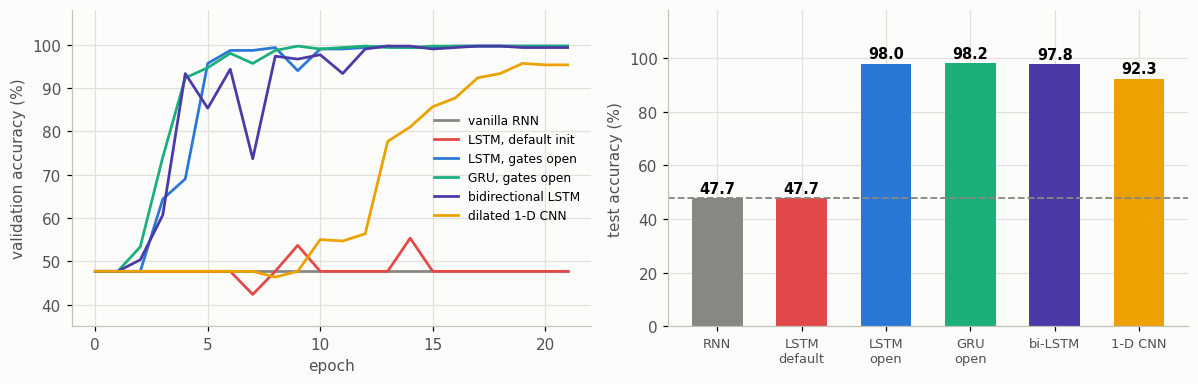

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
COL = {"vanilla RNN": MUTED, "LSTM, default init": RED, "LSTM, gates open": BLUE,
       "GRU, gates open": AQUA, "bidirectional LSTM": VIOLET,
       "dilated 1-D CNN": YELLOW}
for k, v in results.items():
    axes[0].plot(np.array(v["hist"]["acc_va"]) * 100, color=COL[k], label=k)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation accuracy (%)")
axes[0].set_ylim(35, 108); axes[0].legend(fontsize=8, loc="center right")

xs = np.arange(len(results))
vals = [v["test"] * 100 for v in results.values()]
axes[1].bar(xs, vals, color=[COL[k] for k in results], width=.6)
for i, v in enumerate(vals):
    axes[1].text(i, v + 2, f"{v:.1f}", ha="center", fontsize=9.5, fontweight="bold")
axes[1].axhline(majority * 100, color=MUTED, ls="--", lw=1.2)
axes[1].set_xticks(xs)
axes[1].set_xticklabels(["RNN", "LSTM\ndefault", "LSTM\nopen", "GRU\nopen",
                         "bi-LSTM", "1-D CNN"], fontsize=8.5)
axes[1].set_ylabel("test accuracy (%)"); axes[1].set_ylim(0, 118)
plt.tight_layout(); plt.show()

### Reading the table

**The vanilla RNN never leaves the majority class.** Its gradient does not reach the evidence;
there is nothing to learn from. This is not an optimisation problem you can tune away.

**Neither does the default-initialised LSTM** — and that is the result worth remembering.
"Use an LSTM for long-range dependencies" is repeated everywhere, and on a 103-step gap with
default initialisation it is simply false. One line of initialisation separates 48 % from
98 %.

**The bidirectional LSTM does not win.** It is natural to assume that reading the cycle
backwards as well makes the early event easy, and it does — for the *backward* pass, whose
final state sits at $t=0$. But that same backward pass must then carry the *late* factor all
the way back. Each direction has one easy end and one hard end, so bidirectionality costs
twice the parameters and buys nothing here. It earns its keep when the evidence is spread
through the middle of the sequence, not pinned at the ends.

**The dilated CNN is competitive and ten times faster to train**, because it has no sequential
dependency to unroll and its gradient path to the early samples is seven convolutions long
rather than 103 time steps. Its weakness is the fixed receptive field: 255 samples here, which
covers our cycles, but a 400-sample cycle would need more layers.

In [21]:
best = max(results, key=lambda k: results[k]["test"])
yhat = predict(results[best]["model"], test)
print(f"best model: {best}\n")
print(f"{'inclusion':>10}{'heavy':>8}{'n':>6}{'accuracy':>11}   outcome")
for c in (0, 1):
    for hv in (0, 1):
        m_ = (te["chip"] == bool(c)) & (te["heavy"] == bool(hv))
        cls = np.bincount(te["y"][m_], minlength=3).argmax()
        print(f"{str(bool(c)):>10}{str(bool(hv)):>8}{m_.sum():>6}"
              f"{(yhat[m_] == te['y'][m_]).mean():>10.1%}   {CLASSES[cls]}")

cm = np.zeros((3, 3), dtype=int)
for t_, p_ in zip(te["y"], yhat):
    cm[t_, p_] += 1
print("\nconfusion matrix (rows = true):")
print(f"{'':>14}" + "".join(f"{c:>14}" for c in CLASSES))
for i, c in enumerate(CLASSES):
    print(f"{c:>14}" + "".join(f"{v:>14}" for v in cm[i]))
scrap_acc = ((yhat != 1).astype(int) == te["scrap"]).mean()
print(f"\nas a scrap / no-scrap decision: {scrap_acc:.1%}")

best model: GRU, gates open

 inclusion   heavy     n   accuracy   outcome
     False   False   133    100.0%   in tolerance
     False    True   172     97.1%   oversize
      True   False   153     96.1%   undersize
      True    True   142    100.0%   in tolerance

confusion matrix (rows = true):
                   undersize  in tolerance      oversize
     undersize           147             0             0
  in tolerance             6           275             5
      oversize             0             0           167

as a scrap / no-scrap decision: 98.2%


---
## 11. The control: is the information really early?

The claim behind this whole lecture is that the label depends on an event ~103 samples before
the end. That is a claim about the data, and it is testable: train the **same capable model**
on only the last 45 % of every cycle. If the information really is early, this must land at
chance.

In [22]:
%%time
def crop(data, frac=0.45):
    X, O, L, Y = data
    Xc, Oc, Lc = [], [], []
    for i in range(len(Y)):
        T = int(L[i]); s = int(T * (1 - frac))
        Xc.append(X[i, s:T]); Oc.append(O[i, s:T]); Lc.append(T - s)
    Tm = max(Lc)
    Xp = torch.zeros(len(Y), Tm, X.shape[2])
    Op = torch.zeros(len(Y), Tm, dtype=torch.long)
    for i, (a, b) in enumerate(zip(Xc, Oc)):
        Xp[i, :len(a)] = a; Op[i, :len(b)] = b
    return Xp, Op, torch.tensor(Lc), Y


torch.manual_seed(1)
m_late = SeqClassifier("lstm", gate_bias=GATE_BIAS)
train_model(m_late, crop(train), crop(valid), epochs=14)
_, acc_late = evaluate(m_late, crop(test))
print(f"whole cycle     : {results[best]['test']:.1%}")
print(f"last 45 % only  : {acc_late:.1%}")
print(f"majority class  : {majority:.1%}")

whole cycle     : 98.2%
last 45 % only  : 50.7%
majority class  : 47.7%
CPU times: user 22.3 s, sys: 93.6 ms, total: 22.4 s
Wall time: 11.4 s


At chance. The last 45 % of the cycle contains the finishing-pass load — one of the two
factors — and one factor alone is worth nothing, exactly as the 2×2 table predicted. The
model that scores 98 % is genuinely carrying information across the cycle.

Run this control whenever you claim a model learned a long-range dependency. It is cheap, and
it is the difference between a measured claim and a story.

---
## 12. Project two: many-to-many, and generating a cycle

The second project mirrors the book's character-level language model, with load levels instead
of characters. Discretise the spindle current into 48 bins and the problem becomes exactly
next-token prediction: given the tokens so far, predict the next one.

| language model | our model |
|---|---|
| characters | spindle-current bins |
| vocabulary of 80 | vocabulary of 48 |
| `nn.Embedding(80, 256)` | `nn.Embedding(48, 24)` |
| CrossEntropyLoss over characters | CrossEntropyLoss over bins |
| sample a character, append, repeat | sample a bin, append, repeat |

Discretising a continuous signal to make it a classification problem may look odd, but it buys
something real: the model predicts a full **distribution** over the next value rather than a
point estimate, so it can represent "either still cutting at 11 A, or the tool has just
retracted to 1 A" — which a squared-error forecaster cannot.

In [23]:
N_BINS, BIN_LO, BIN_HI, SEQ_LEN = 48, -1.0, 16.0, 60


def to_tokens(cur):
    edges = np.linspace(BIN_LO, BIN_HI, N_BINS + 1)[1:-1]
    return np.digitize(cur, edges).astype(np.int64)


def token_centres():
    e = np.linspace(BIN_LO, BIN_HI, N_BINS + 1)
    return 0.5 * (e[:-1] + e[1:])


class LoadLM(nn.Module):
    def __init__(self, vocab=N_BINS, embed_dim=24, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, embed_dim)
        self.hidden = hidden
        self.rnn = nn.LSTM(embed_dim, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, vocab)      # logits, not probabilities

    def forward(self, x, state=None):
        out, state = self.rnn(self.emb(x), state)
        return self.fc(out), state

    def init_state(self, n=1):
        return (torch.zeros(1, n, self.hidden), torch.zeros(1, n, self.hidden))


toks = [to_tokens(x[:, 0]) for x in tr["x"]]
chunks = [t[i:i + SEQ_LEN + 1] for t in toks
          for i in range(0, len(t) - SEQ_LEN - 1, SEQ_LEN // 2)]
arr = torch.tensor(np.array(chunks))
print(f"{len(chunks)} training chunks of {SEQ_LEN}+1 tokens")
print("inputs  x :", arr[0, :-1][:12].numpy(), "...")
print("targets y :", arr[0, 1:][:12].numpy(), "...   (shifted by one)")

2177 training chunks of 60+1 tokens
inputs  x : [1 1 3 4 7 6 7 7 7 5 6 2] ...
targets y : [1 3 4 7 6 7 7 7 5 6 2 2] ...   (shifted by one)


In [24]:
%%time
ds = TensorDataset(arr[:, :-1], arr[:, 1:])
g = torch.Generator().manual_seed(1)
dl = DataLoader(ds, batch_size=64, shuffle=True, generator=g, drop_last=True)

torch.manual_seed(1)
lm = LoadLM()
opt = torch.optim.Adam(lm.parameters(), lr=3e-3)
lm_hist = []
for ep in range(14):
    tot = 0.0
    for xb, yb in dl:
        logits, _ = lm(xb)
        loss = loss_fn(logits.reshape(-1, N_BINS), yb.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(lm.parameters(), 1.0)
        opt.step(); opt.zero_grad()
        tot += loss.item() * len(xb)
    lm_hist.append(tot / len(ds))
    if ep % 4 == 0 or ep == 13:
        print(f"  epoch {ep:3d}  loss {lm_hist[-1]:.4f}"
              f"   perplexity {math.exp(lm_hist[-1]):.1f} of {N_BINS} bins")

  epoch   0  loss 2.9437   perplexity 19.0 of 48 bins


  epoch   4  loss 1.7315   perplexity 5.6 of 48 bins


  epoch   8  loss 1.6373   perplexity 5.1 of 48 bins


  epoch  12  loss 1.5946   perplexity 4.9 of 48 bins


  epoch  13  loss 1.5860   perplexity 4.9 of 48 bins
CPU times: user 28 s, sys: 2.9 s, total: 30.9 s
Wall time: 15.8 s


### Sampling, and the temperature

The model outputs **logits**, not a choice. Taking the arg-max at every step makes the model
deterministic and it will lock into a constant. Instead we sample from the categorical
distribution the logits define — and we can scale the logits by $\alpha$ before sampling:

$$P(k)=\frac{\exp(\alpha z_k)}{\sum_j \exp(\alpha z_j)}$$

$\alpha>1$ sharpens the distribution (more predictable, more repetitive); $\alpha<1$ flattens
it (more varied, more nonsense). It is the reciprocal of the "temperature" you see in text
generation. Feeding the model's own output back as its next input is **autoregression**.

In [25]:
logits_demo = torch.tensor([[1.0, 1.0, 3.0]])
for a in (0.1, 0.5, 1.0, 2.0):
    p = F.softmax(a * logits_demo, dim=1).numpy()[0]
    print(f"α = {a:>4}:  {p.round(3)}")
print("\nα → 0 gives a uniform choice; α → ∞ gives the arg-max")

α =  0.1:  [0.31  0.31  0.379]
α =  0.5:  [0.212 0.212 0.576]
α =  1.0:  [0.107 0.107 0.787]
α =  2.0:  [0.018 0.018 0.965]

α → 0 gives a uniform choice; α → ∞ gives the arg-max


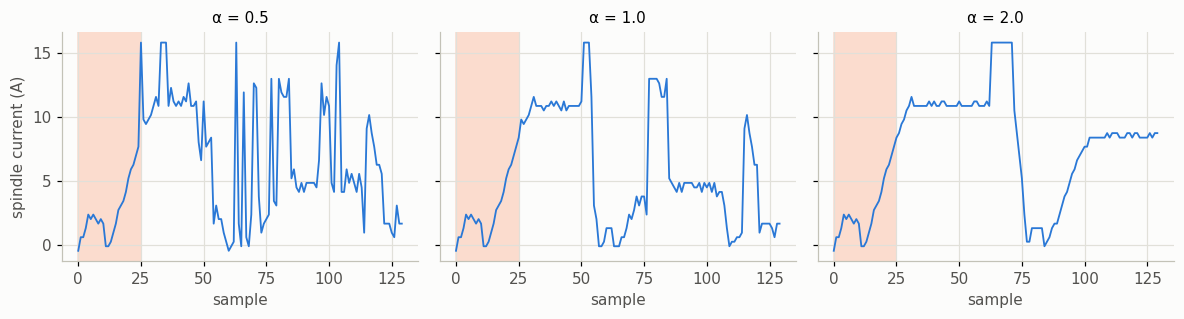

α = 0.5 jumps between bins constantly; α = 2.0 produces long flat plateaux
and clean phase transitions, which is what a real cycle looks like.


In [26]:
@torch.no_grad()
def sample_cycle(model, seed_tokens, n_generate=105, scale=1.0, seed=5):
    torch.manual_seed(seed)
    model.eval()
    state = model.init_state(1)
    gen = list(seed_tokens)
    logits, state = model(torch.tensor(gen, dtype=torch.long)[None], state)
    last = logits[0, -1]
    for _ in range(n_generate):
        nxt = int(torch.distributions.Categorical(logits=last * scale).sample())
        gen.append(nxt)
        logits, state = model(torch.tensor([[nxt]]), state)
        last = logits[0, -1]
    return np.array(gen)


centres = token_centres()
seed_tokens = to_tokens(tr["x"][3][:, 0][:25])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.0), sharey=True)
for ax, sc in zip(axes, (0.5, 1.0, 2.0)):
    gen = sample_cycle(lm, seed_tokens, scale=sc)
    ax.plot(centres[gen], color=BLUE, lw=1.2)
    ax.axvspan(0, len(seed_tokens), color="#fbdcce", zorder=0)
    ax.set_title(f"α = {sc}", fontsize=10)
    ax.set_xlabel("sample")
axes[0].set_ylabel("spindle current (A)")
plt.tight_layout(); plt.show()
print("α = 0.5 jumps between bins constantly; α = 2.0 produces long flat plateaux"
      "\nand clean phase transitions, which is what a real cycle looks like.")

---
## 13. Where this runs out: a preview of attention

Everything above funnels a sequence through **one fixed-width vector**. Our LSTM compresses
130 samples into 48 numbers and the classifier head sees only those. That works here, but
notice what we had to do to make it work: hand-initialise a gate so a single bit could survive
103 steps of being multiplied by $f_t$.

Attention removes the bottleneck. Instead of forcing the past through a recurrent state, it
lets the read-out look at **every** time step directly and weight them:

$$\text{context} = \sum_{t=1}^{T}\alpha_t\,h^{(t)},
\qquad \alpha_t=\frac{\exp(s_t)}{\sum_j \exp(s_j)}$$

where $s_t$ is a learned score for step $t$. The gradient path from the loss to $h^{(25)}$ is
now **one multiplication**, not 103. Below is the simplest possible version — a single learned
query scoring each step — applied to our already-trained LSTM's hidden states, purely to see
what the weights look like.

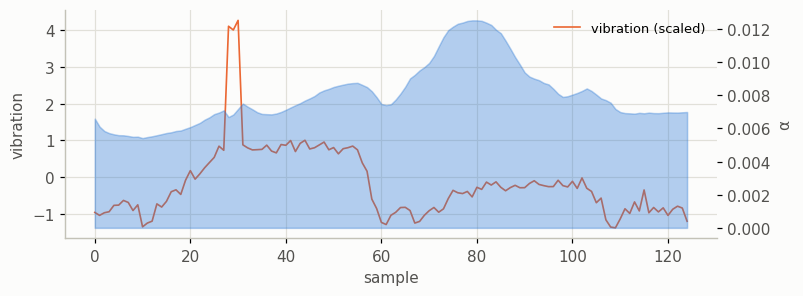

These weights are UNTRAINED -- the point is the shape of the mechanism, not
the values. Chapter 16 learns the scores, and the transformer drops the
recurrence entirely, keeping only this weighted read-out.


In [27]:
# a minimal additive-attention read-out over the hidden states of one cycle
torch.manual_seed(0)
m = results["LSTM, gates open"]["model"]
i = int(np.where(te["chip"] & ~te["heavy"])[0][0])
X, O, L, Y = test
with torch.no_grad():
    z = torch.cat([X[i:i+1, :int(L[i])], m.emb(O[i:i+1, :int(L[i])])], -1)
    hs, _ = m.rnn(z)                               # (1, T, hidden)

score = nn.Linear(HID, 1, bias=False)
with torch.no_grad():                              # a query that likes big changes
    score.weight.copy_(torch.randn(1, HID) * 0.1)
alpha = F.softmax(score(hs)[0, :, 0], dim=0).detach().numpy()

fig, ax = plt.subplots(figsize=(7.4, 2.8))
ax.plot(X[i, :int(L[i]), 1].numpy(), color=ORANGE, lw=1.1, label="vibration (scaled)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.fill_between(np.arange(len(alpha)), alpha, color=BLUE, alpha=.35,
                 label="attention weight")
ax.set_xlabel("sample"); ax.set_ylabel("vibration"); ax2.set_ylabel("α")
ax.legend(fontsize=8.5, loc="upper right"); plt.tight_layout(); plt.show()
print("These weights are UNTRAINED -- the point is the shape of the mechanism, not")
print("the values. Chapter 16 learns the scores, and the transformer drops the")
print("recurrence entirely, keeping only this weighted read-out.")

---
## 14. The protocol — what to remember

1. **Pick the shape first.** Many-to-one, one-to-many, synchronised or delayed many-to-many
   decides where you read the output from and what the loss is computed over.
2. **Never shuffle within a sequence.** Shuffle the sequences, not their samples.
3. **Fit the scaler on the training split only**, per channel, and apply it before padding.
4. **Pad, then pack.** Without `pack_padded_sequence`, `hidden[-1]` is the state after the
   padding, not after the data.
5. **Measure the gradient reach before you choose the architecture.** It takes seconds and it
   tells you whether the dependency you care about is even visible.
6. **Initialise the forget gate open** (bias ≈ 1–2) for anything over ~50 steps. It is one
   line and it was worth 50 accuracy points here.
7. **Clip gradients** — it costs nothing and it turns an exploding run into a slow one. It
   does not help with vanishing gradients.
8. **Never truncate BPTT shorter than the dependency you need.** Truncation is a memory
   decision with an accuracy consequence.
9. **Generate by sampling, not arg-max**, and expose the temperature. Arg-max rollouts
   collapse.
10. **Run the ablation that could falsify your claim.** Hiding the early window and landing at
    chance is what turned "the model learned a long-range dependency" into a measurement.

---
## 15. Exercises

1. **Forward pass by hand, two layers.** Extend the manual computation in section 3 to
   `nn.RNN(..., num_layers=2)`. Which weights does layer 2 use, and what is its input at step
   $t$? Verify against `nn.RNN` to float32 precision.

2. **Find the breaking distance.** Regenerate the data with the inclusion placed at
   10 %, 30 %, 50 % and 70 % of the way through the cycle, and plot test accuracy against the
   gap for the default-init LSTM and the gates-open LSTM. Where does the default version start
   to fail, and does that match the gradient-reach curve from section 5?

3. **Sweep the gate bias.** Train the LSTM with forget-gate bias in {0, 0.5, 1, 2, 4} and plot
   test accuracy. Is there an upper limit, and what would going too far cost you? (Think about
   what a cell that never forgets does on a long sequence.)

4. **Truncation, measured.** Implement TBPTT with $k \in \{10, 30, 60, 130\}$ on the
   gates-open LSTM and plot accuracy against $k$. Confirm that accuracy collapses once $k$ is
   below the gap, and report the wall-clock saving at each $k$.

5. **Make the bidirectional model win.** Modify the generator so the decisive evidence sits in
   the *middle* of the cycle rather than at the two ends. Re-run the six models. Does the
   bidirectional LSTM now beat the unidirectional one, and by how much?

6. **Synchronised many-to-many.** Change the task: instead of one label per cycle, predict a
   per-sample flag that is 1 while the tool is in cut. You will need `batch_first` outputs
   rather than the final hidden state, a loss masked by the true lengths, and no `hidden[-1]`
   at all. Report accuracy on the padded region to prove your mask works.

7. **Regression instead of bins.** Replace the 48-bin language model with a model that
   predicts the next current value directly under an MSE loss, and roll it out
   autoregressively. Compare the generated cycles with the sampled ones. What does the MSE
   model do at the phase transitions, and why?

8. **Cost-weighted decisions.** Scrapping a good part costs one part; shipping an oversize part
   costs a warranty claim worth 50. Using the softmax probabilities of the best model, choose
   the class that minimises expected cost rather than the arg-max, and report the new confusion
   matrix and the change in total cost.

---
## 16. References

**Book chapter this lecture follows**

* Raschka, S., Liu, Y. & Mirjalili, V. (2022). *Machine Learning with PyTorch and
  Scikit-Learn*, Chapter 15: "Modeling Sequential Data Using Recurrent Neural Networks". Packt.

**Papers**

* Werbos, P. J. (1990). Backpropagation through time: what it does and how to do it.
  *Proceedings of the IEEE* 78(10):1550–1560.
* Hochreiter, S. & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*
  9(8):1735–1780.
* Gers, F. A., Schmidhuber, J. & Cummins, F. (2000). Learning to forget: continual prediction
  with LSTM. *Neural Computation* 12(10):2451–2471. (The forget gate, and why its bias
  matters.)
* Bengio, Y., Simard, P. & Frasconi, P. (1994). Learning long-term dependencies with gradient
  descent is difficult. *IEEE Transactions on Neural Networks* 5(2):157–166.
* Pascanu, R., Mikolov, T. & Bengio, Y. (2013). On the difficulty of training recurrent neural
  networks. *ICML 2013*. (Gradient clipping, and the spectral-radius condition.)
* Cho, K. et al. (2014). Learning phrase representations using RNN encoder–decoder for
  statistical machine translation. *EMNLP 2014*. (The GRU.)
* Chung, J., Gulcehre, C., Cho, K. & Bengio, Y. (2014). Empirical evaluation of gated recurrent
  neural networks on sequence modeling. arXiv:1412.3555.
* Jozefowicz, R., Zaremba, W. & Sutskever, I. (2015). An empirical exploration of recurrent
  network architectures. *ICML 2015*. (Measures the forget-gate bias systematically and
  recommends initialising it to 1.)
* Sutskever, I., Martens, J. & Hinton, G. (2011). Generating text with recurrent neural
  networks. *ICML 2011*.
* Bahdanau, D., Cho, K. & Bengio, Y. (2015). Neural machine translation by jointly learning to
  align and translate. *ICLR 2015*. (Attention — where chapter 16 begins.)
* Bai, S., Kolter, J. Z. & Koltun, F. (2018). An empirical evaluation of generic convolutional
  and recurrent networks for sequence modeling. arXiv:1803.01271. (The dilated-convolution
  baseline.)
* Karpathy, A. (2015). The unreasonable effectiveness of recurrent neural networks.
  <http://karpathy.github.io/2015/05/21/rnn-effectiveness/> (The source of the
  many-to-one / one-to-many diagram.)

**Documentation**

* `nn.RNN`, `nn.LSTM`, `nn.GRU` — <https://pytorch.org/docs/stable/nn.html#recurrent-layers>
* `pack_padded_sequence` — <https://pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html>
* `torch.distributions.Categorical` — <https://pytorch.org/docs/stable/distributions.html>

**Domain background**

* ISO 230-3:2020, *Test code for machine tools — Determination of thermal effects.* (Where the
  thermal-growth term in the error budget comes from.)
* Altintas, Y. (2012). *Manufacturing Automation: Metal Cutting Mechanics, Machine Tool
  Vibrations, and CNC Design*, 2nd ed. Cambridge University Press. (Tool deflection and
  chatter.)
* Teti, R., Jemielniak, K., O'Donnell, G. & Dornfeld, D. (2010). Advanced monitoring of
  machining operations. *CIRP Annals* 59(2):717–739. (What real spindle-current and vibration
  monitoring looks like.)

> **A note on the book's own code.** Chapter 15 builds both of its projects on `torchtext`
> (for the IMDb sentiment task) and a Project Gutenberg download (for the text generator).
> PyTorch deprecated and archived `torchtext` in 2024, and the `torchtext.vocab.Vocab` API used
> in the chapter no longer exists. The mechanics in this notebook are the chapter's; only the
> data pipeline has been replaced.